# MoveEnetOFK — tutte le figure del paper

**Eseguire tutte le celle.** Questo notebook lancia `generate_all_figures.py` e visualizza le **figure separate** in `output/`.

La versione precedente generava una sola anteprima. Questa versione esporta **14 figure differenti** (42 PDF/SVG/PNG) usando le tabelle numeriche già incluse e tutte quelle aggiunte in `sources.json`.

Non vengono inventati né ricostruiti intervalli di confidenza non presenti negli input. L'ablation Move-IIT usa un'analisi su **59 sequenze** con PCK normalizzato sui **joint 1 e 5**. L'energia–accuratezza Move-IIT usa **12 sequenze** e NON viene mescolata con l'ablation da 59 sequenze.


In [1]:
from pathlib import Path
import json, subprocess, sys
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/'generate_all_figures.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Apri il notebook dalla cartella paper_figures')
CONFIG = ROOT/'sources.json'
print('Package:', ROOT)
print('Config:', CONFIG)


Package: /workspace/moveEnetFlow/analysis/paper_figures
Config: /workspace/moveEnetFlow/analysis/paper_figures/sources.json


## 1. Sorgenti e dati mancanti

Modifica `sources.json` **prima** di rieseguire le celle se vuoi collegare i CSV completi: `accuracy_rate.eh36m`, `accuracy_rate.dhp19`, `energy_rtf.eh36m`, `energy_rtf.dhp19`.

Per trovare file idonei:

```bash
python generate_all_figures.py --scan /data/MoveEnet_OFK_results
```

**Attenzione:** il notebook principale ExpA eH36M/DHP19 usava storicamente i joint **2 e 6** per PCK: per quei CSV, il PCK viene omesso per sicurezza finché non certifichi che è stato **ricalcolato** con 1 e 5 e imposti `expa_pck_1_5_recomputed: true` in `sources.json`. L'MPJPE rimane disponibile.


In [2]:
config = json.loads(CONFIG.read_text())
print(json.dumps(config, ensure_ascii=False, indent=2))


{
  "energy_accuracy": {
    "all": "data/energy_accuracy_preview.csv"
  },
  "accuracy_rate": {
    "eh36m": null,
    "dhp19": null,
    "moveiit": "data/cached_moveiit_ablation_59.csv"
  },
  "energy_rtf": {
    "eh36m": null,
    "dhp19": null,
    "moveiit": "data/cached_moveiit_rtf_12.csv"
  },
  "expa_ofk_flow_hz": 200,
  "baseline_source_flow_hz": 200,
  "expa_pck_1_5_recomputed": false
}


## 2. Genera e salva **tutte** le figure disponibili

Questo è il comando principale. Il file `output/FIGURE_MANIFEST.md` distingue file generati e dati ancora mancanti.


In [3]:
run = subprocess.run([sys.executable, str(ROOT/'generate_all_figures.py'), '--config', str(CONFIG)],
                     cwd=str(ROOT), text=True, capture_output=True)
print(run.stdout)
if run.returncode:
    print('ERRORI:', run.stderr)
    raise RuntimeError('Generation failed. Read errors above.')


OK output/energy_accuracy/eh36m/mpjpe
OK output/energy_accuracy/eh36m/pck
OK output/energy_accuracy/eh36m/mpjpe_pck_pair
OK output/energy_accuracy/dhp19/mpjpe
OK output/energy_accuracy/dhp19/pck
OK output/energy_accuracy/dhp19/mpjpe_pck_pair
OK output/energy_accuracy/moveiit/mpjpe
OK output/energy_accuracy/moveiit/pck
OK output/energy_accuracy/moveiit/mpjpe_pck_pair
OK output/energy_accuracy/all_datasets
OK output/accuracy_rate/moveiit/mpjpe
OK output/accuracy_rate/moveiit/pck
OK output/accuracy_rate/moveiit/mpjpe_pck_pair
OK output/energy_rtf/moveiit

EXPORTED 14 figures x 3 formats = 42 files
MISSING 4 | ERRORS 0
Manifest: /workspace/moveEnetFlow/analysis/paper_figures/output/FIGURE_MANIFEST.md



## 3. Elenco dei file esportati

PDF per LaTeX, SVG modificabile e PNG per controllo. Ogni figura è anche accompagnata dal relativo `.meta.json` di provenienza.


In [4]:
rows=[]
for png in sorted((ROOT/'output').rglob('*.png')):
    rows.append({'Figura':str(png.relative_to(ROOT/'output')).replace('.png',''),
                 'PNG':str(png.relative_to(ROOT)),'PDF':str(png.with_suffix('.pdf').relative_to(ROOT)),
                 'SVG':str(png.with_suffix('.svg').relative_to(ROOT))})
display(pd.DataFrame(rows))
print('Totale figure PNG:',len(rows))


,Figura,PNG,PDF,SVG
0,accuracy_rate/moveiit/mpjpe,output/accuracy_rate/moveiit/mpjpe.png,output/accuracy_rate/moveiit/mpjpe.pdf,output/accuracy_rate/moveiit/mpjpe.svg
1,accuracy_rate/moveiit/mpjpe_pck_pair,output/accuracy_rate/moveiit/mpjpe_pck_pair.png,output/accuracy_rate/moveiit/mpjpe_pck_pair.pdf,output/accuracy_rate/moveiit/mpjpe_pck_pair.svg
2,accuracy_rate/moveiit/pck,output/accuracy_rate/moveiit/pck.png,output/accuracy_rate/moveiit/pck.pdf,output/accuracy_rate/moveiit/pck.svg
3,energy_accuracy/all_datasets,output/energy_accuracy/all_datasets.png,output/energy_accuracy/all_datasets.pdf,output/energy_accuracy/all_datasets.svg
4,energy_accuracy/dhp19/mpjpe,output/energy_accuracy/dhp19/mpjpe.png,output/energy_accuracy/dhp19/mpjpe.pdf,output/energy_accuracy/dhp19/mpjpe.svg
5,energy_accuracy/dhp19/mpjpe_pck_pair,output/energy_accuracy/dhp19/mpjpe_pck_pair.png,output/energy_accuracy/dhp19/mpjpe_pck_pair.pdf,output/energy_accuracy/dhp19/mpjpe_pck_pair.svg
6,energy_accuracy/dhp19/pck,output/energy_accuracy/dhp19/pck.png,output/energy_accuracy/dhp19/pck.pdf,output/energy_accuracy/dhp19/pck.svg
7,energy_accuracy/eh36m/mpjpe,output/energy_accuracy/eh36m/mpjpe.png,output/energy_accuracy/eh36m/mpjpe.pdf,output/energy_accuracy/eh36m/mpjpe.svg
8,energy_accuracy/eh36m/mpjpe_pck_pair,output/energy_accuracy/eh36m/mpjpe_pck_pair.png,output/energy_accuracy/eh36m/mpjpe_pck_pair.pdf,output/energy_accuracy/eh36m/mpjpe_pck_pair.svg
9,energy_accuracy/eh36m/pck,output/energy_accuracy/eh36m/pck.png,output/energy_accuracy/eh36m/pck.pdf,output/energy_accuracy/eh36m/pck.svg


Totale figure PNG: 14


## 4. Visualizza le immagini una alla volta

Per evitare di visualizzare 14 figure se non ti servono tutte, modifica `SHOW_FAMILY` scegliendo `all`, `energy_accuracy`, `accuracy_rate`, `energy_rtf`. Il codice mostra **file diversi**, non la stessa figura ripetuta.


**accuracy_rate/moveiit/mpjpe.png**

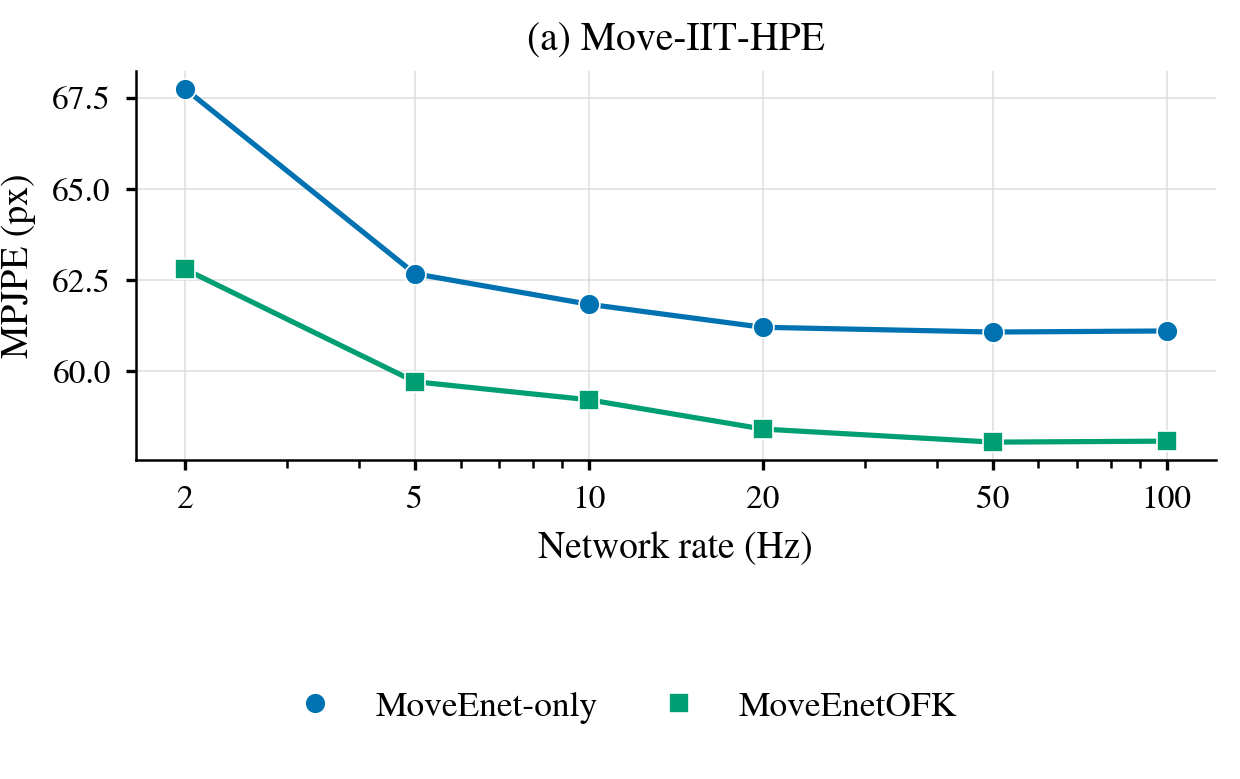

**accuracy_rate/moveiit/mpjpe_pck_pair.png**

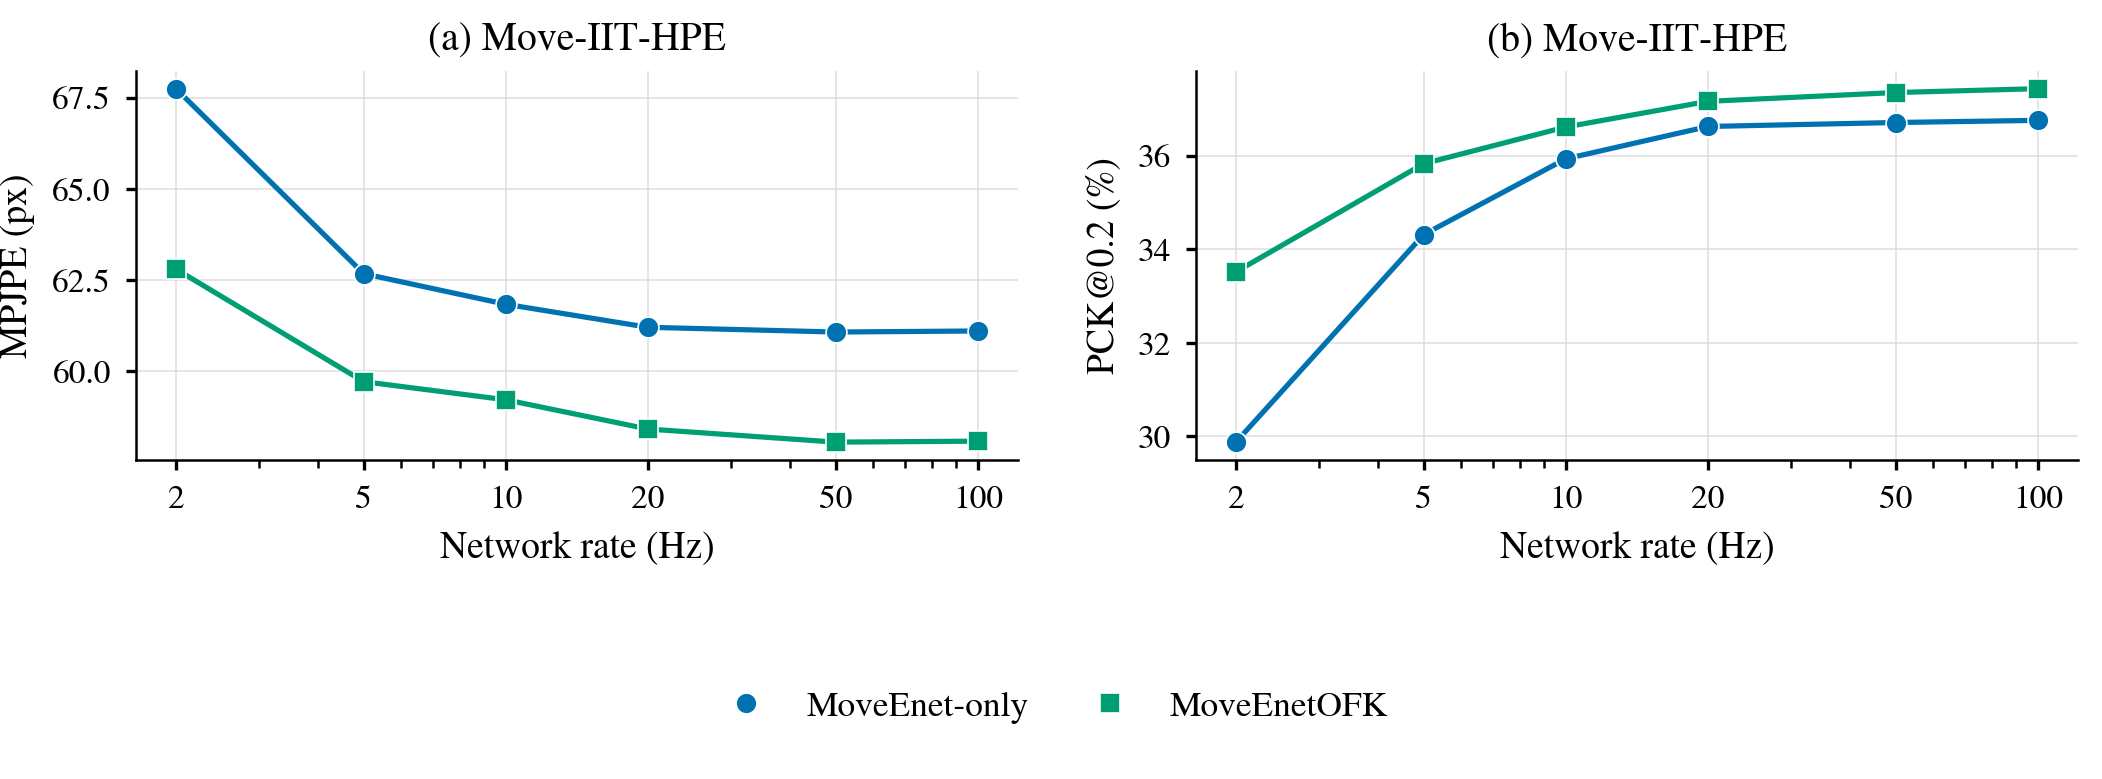

**accuracy_rate/moveiit/pck.png**

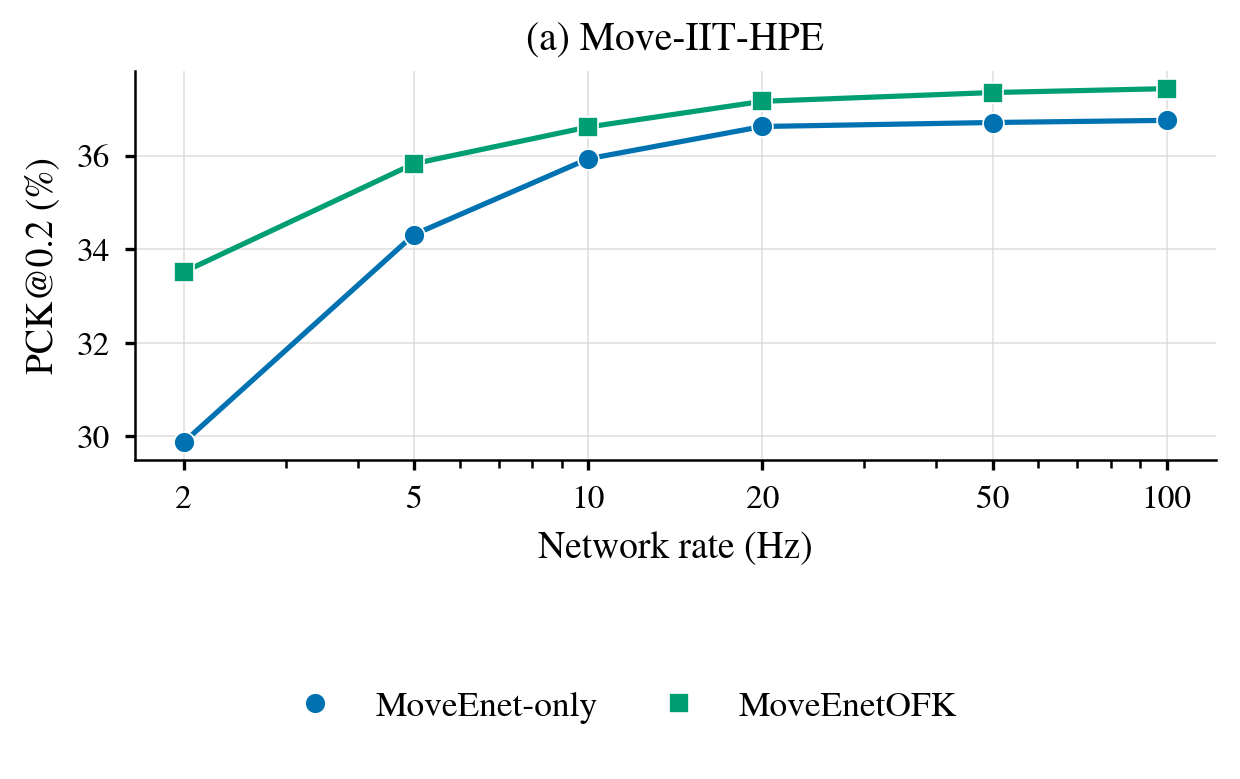

**energy_accuracy/all_datasets.png**

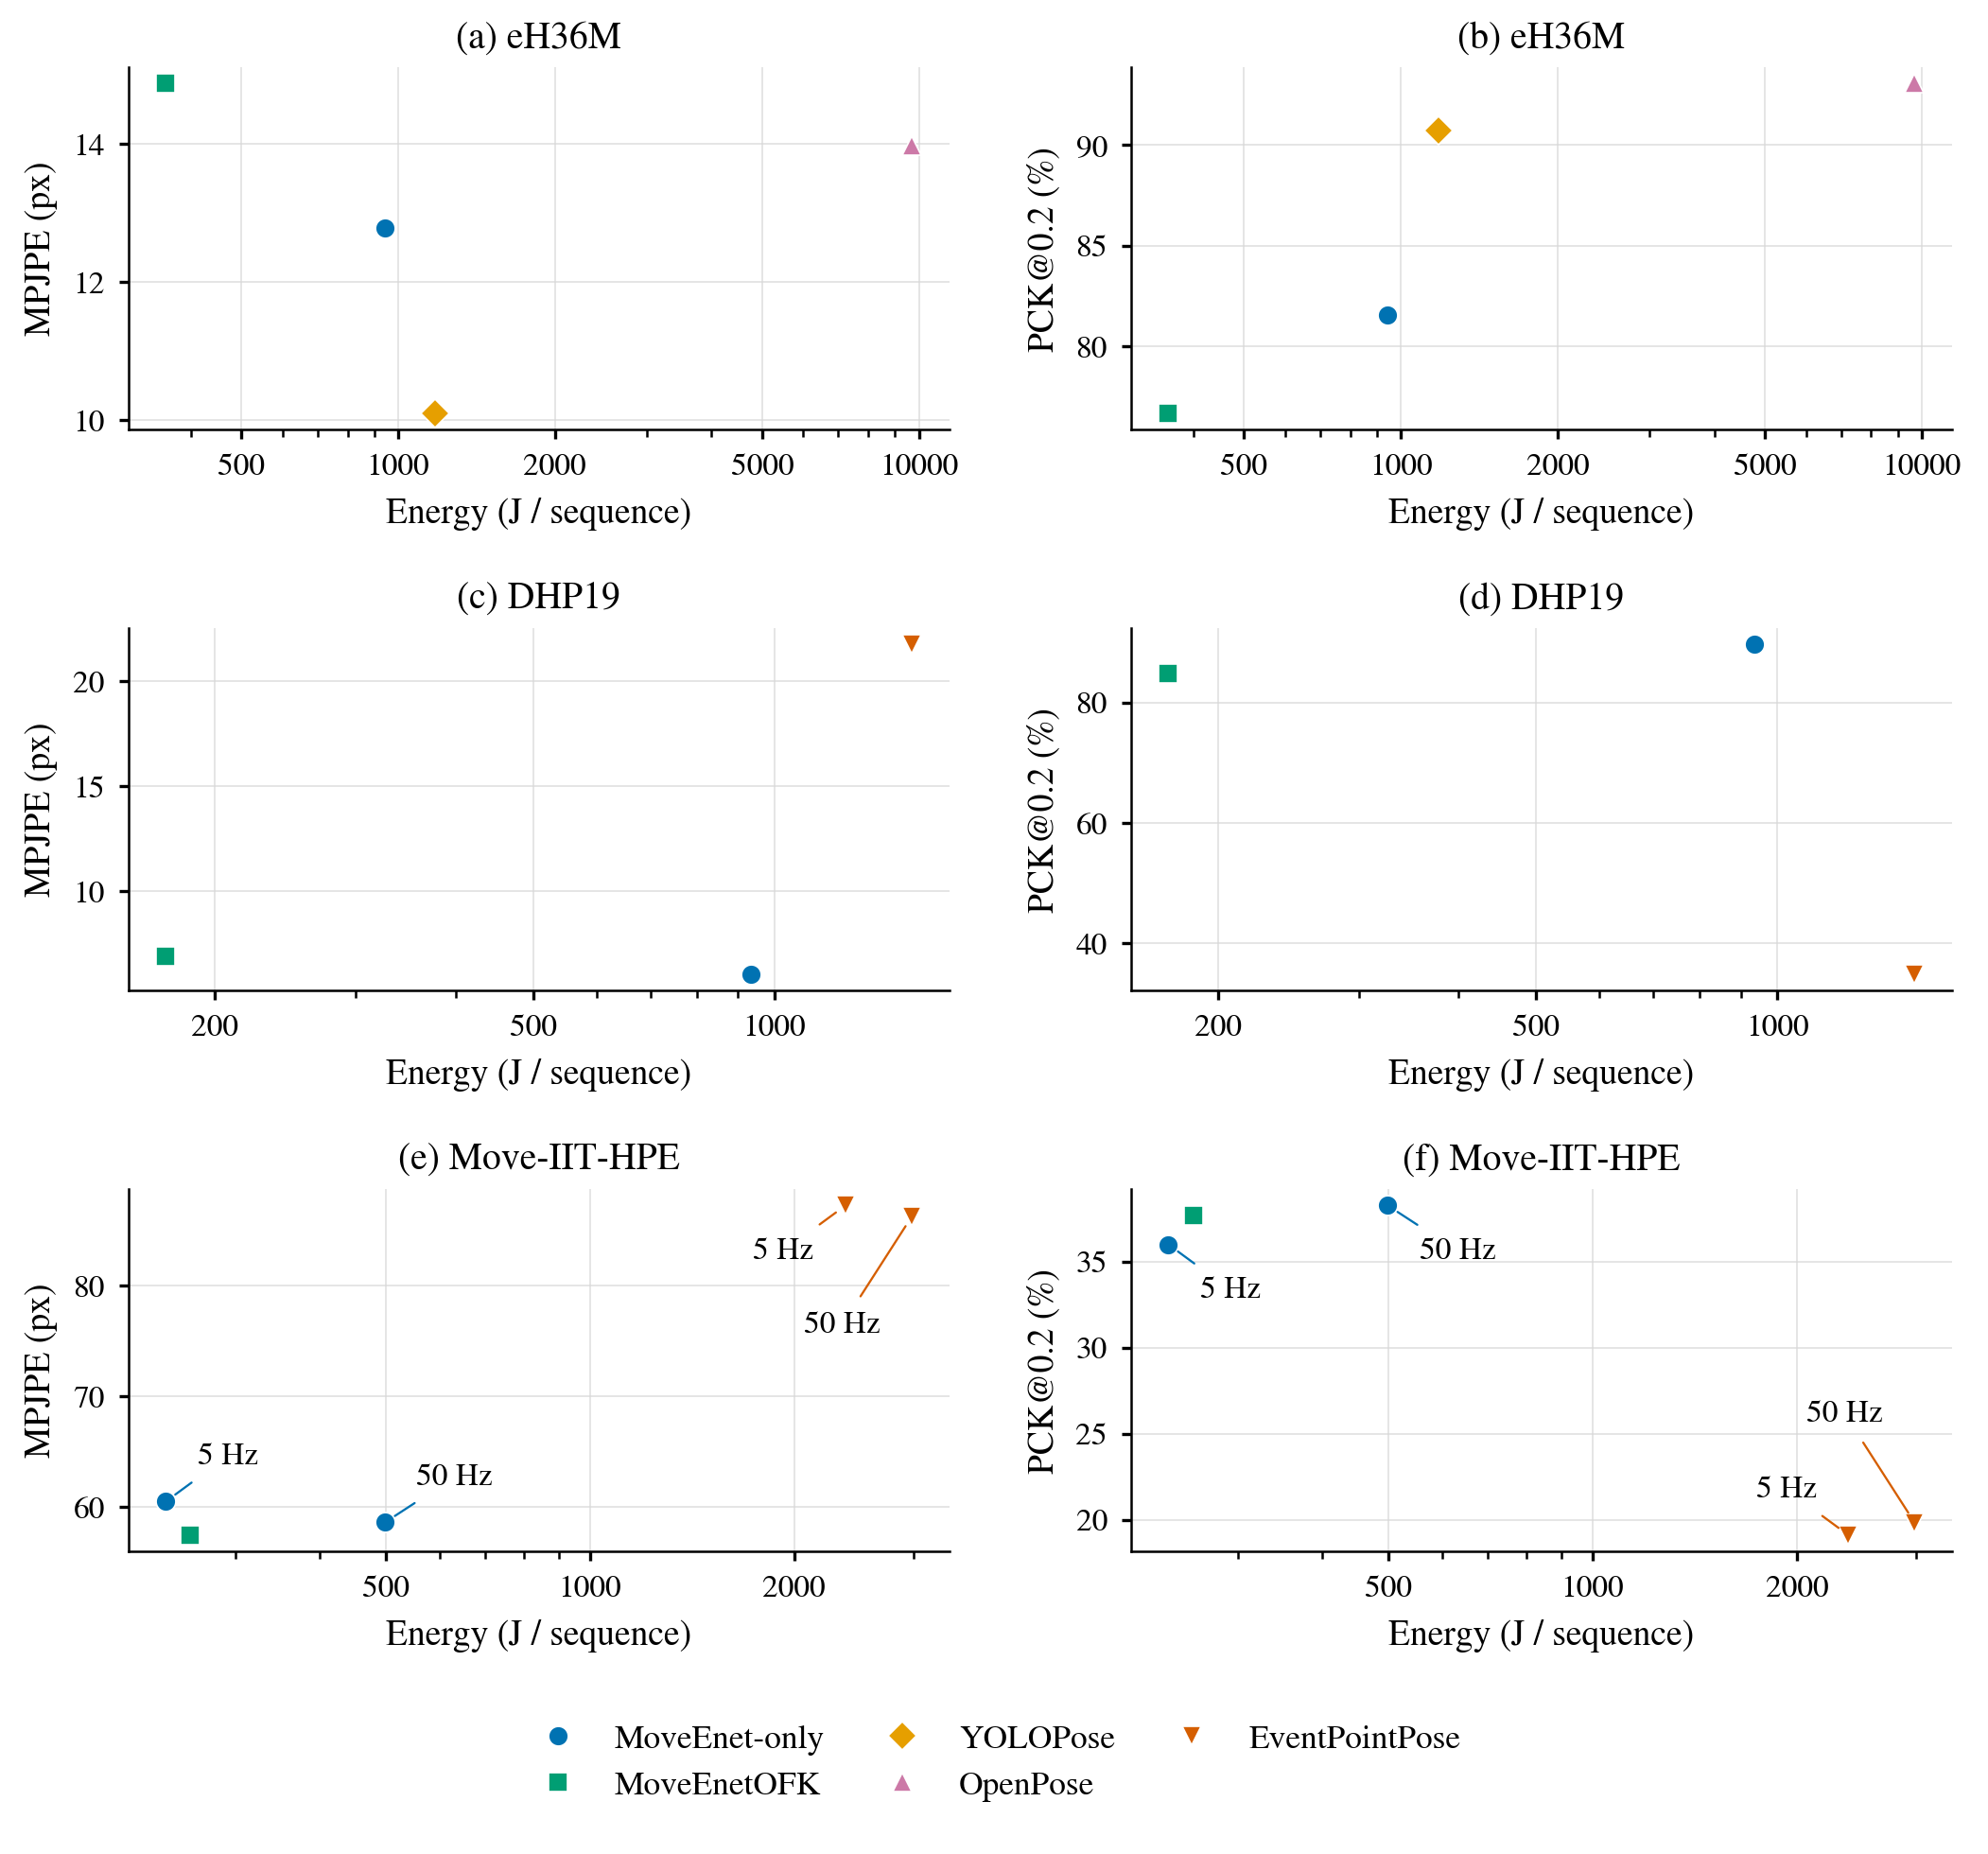

**energy_accuracy/dhp19/mpjpe.png**

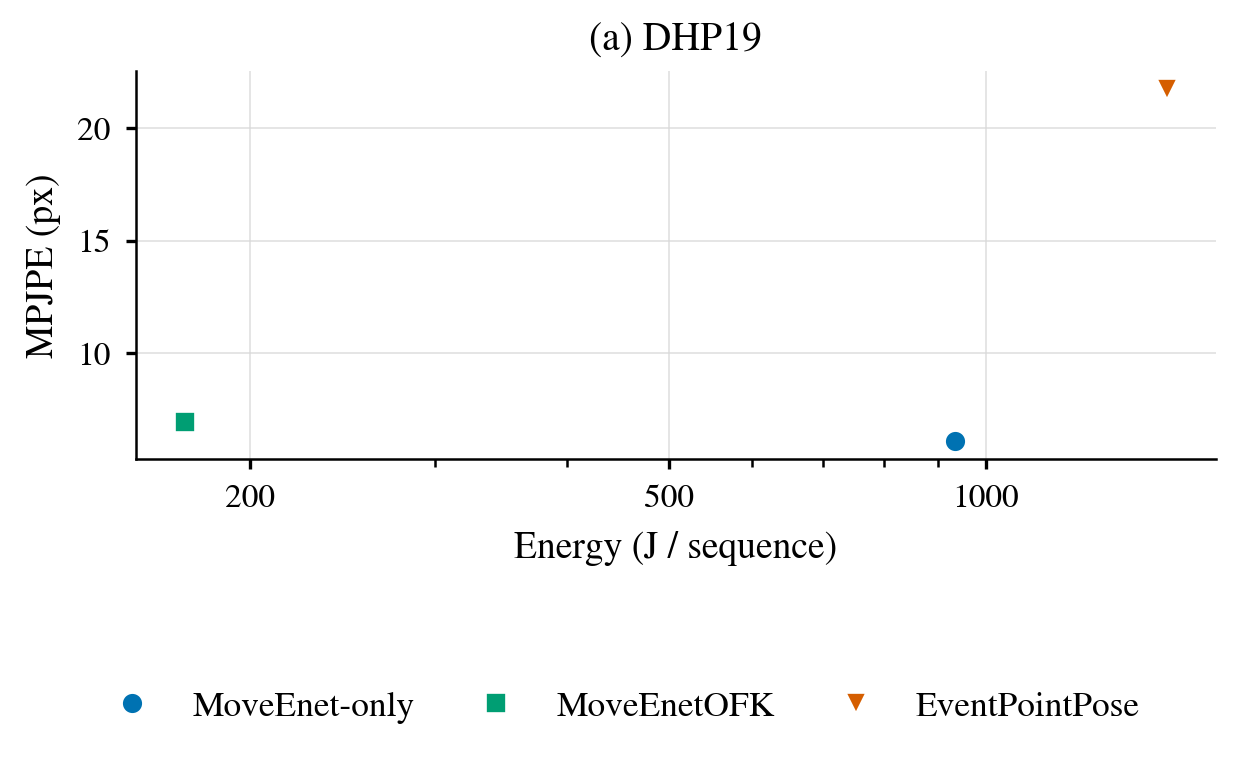

**energy_accuracy/dhp19/mpjpe_pck_pair.png**

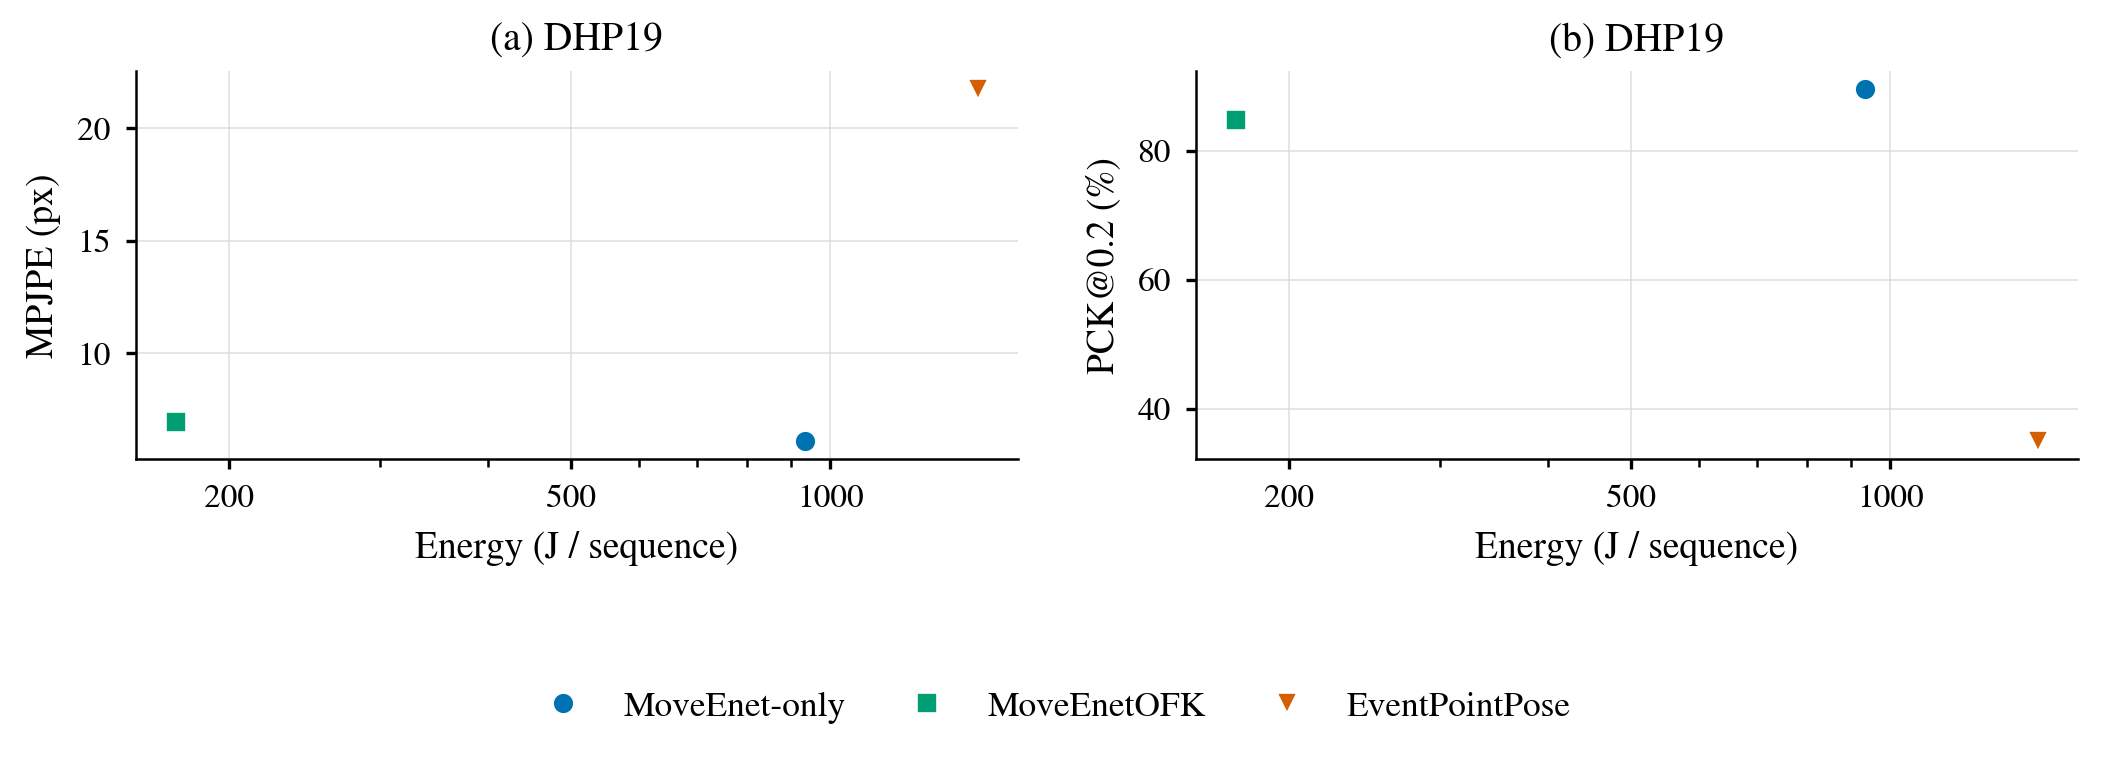

**energy_accuracy/dhp19/pck.png**

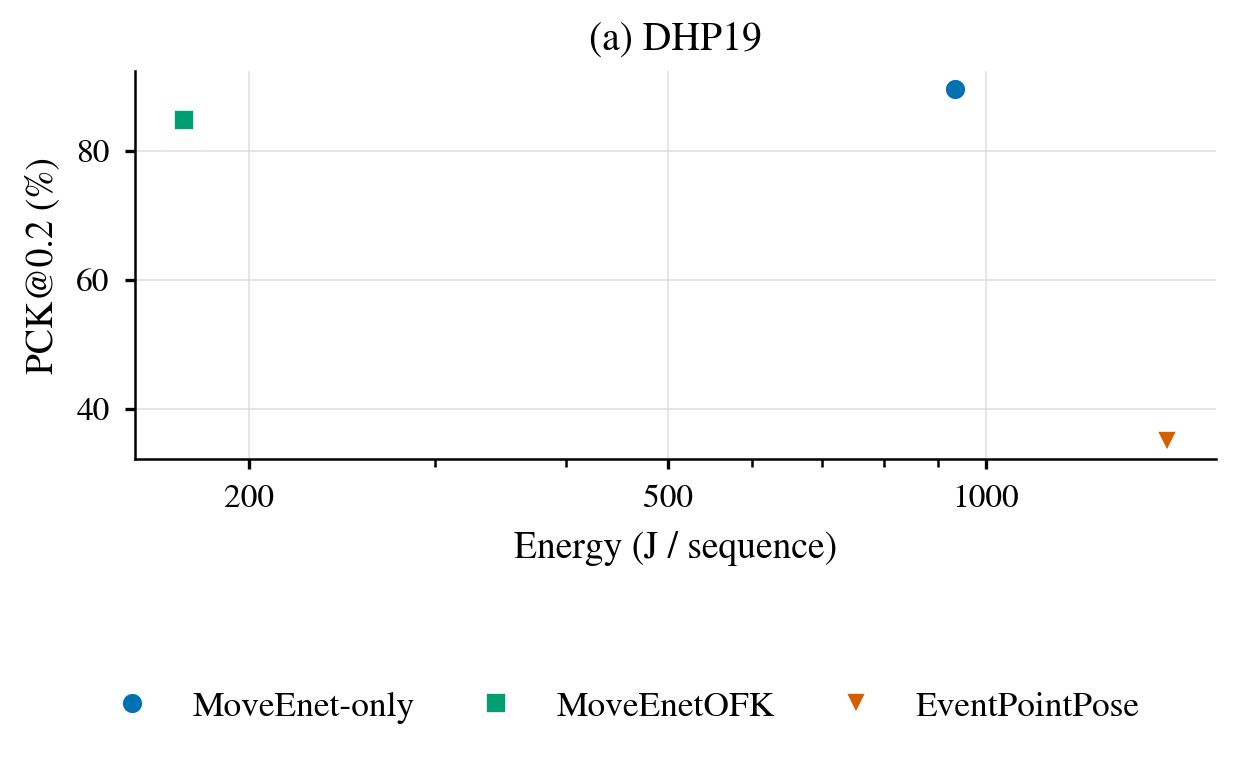

**energy_accuracy/eh36m/mpjpe.png**

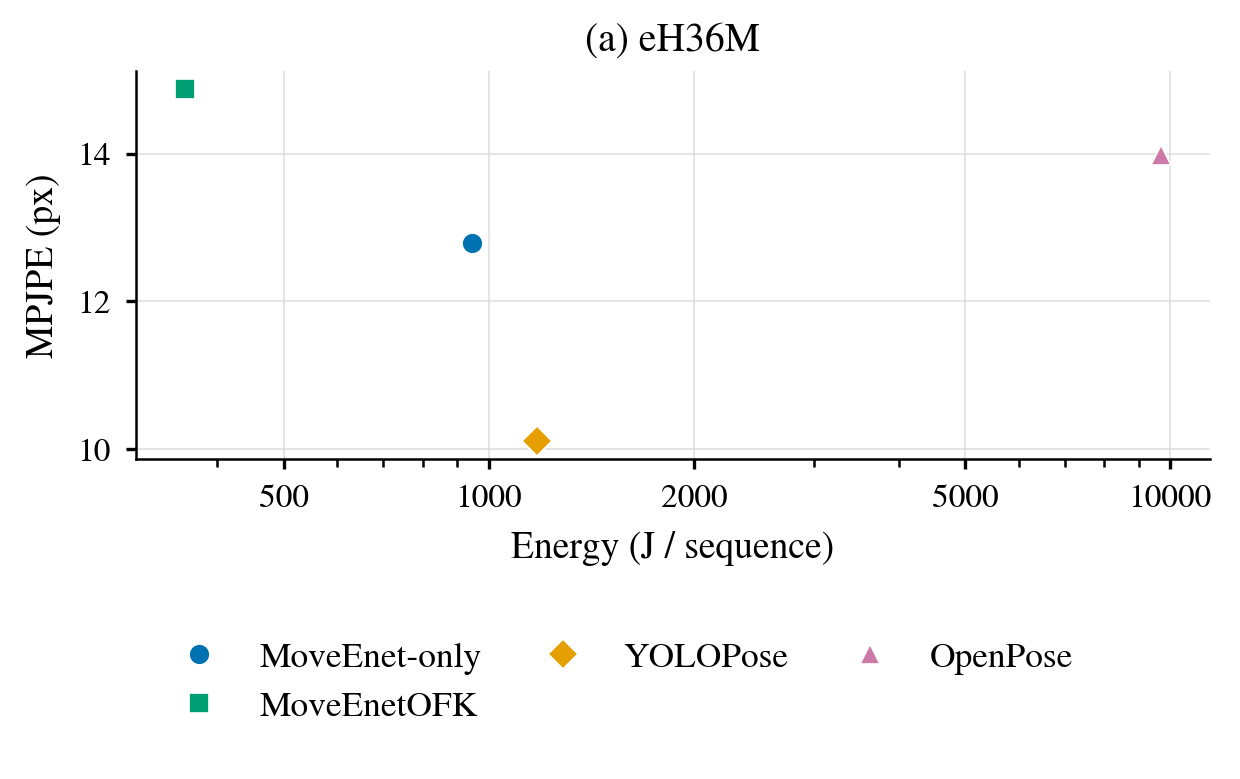

**energy_accuracy/eh36m/mpjpe_pck_pair.png**

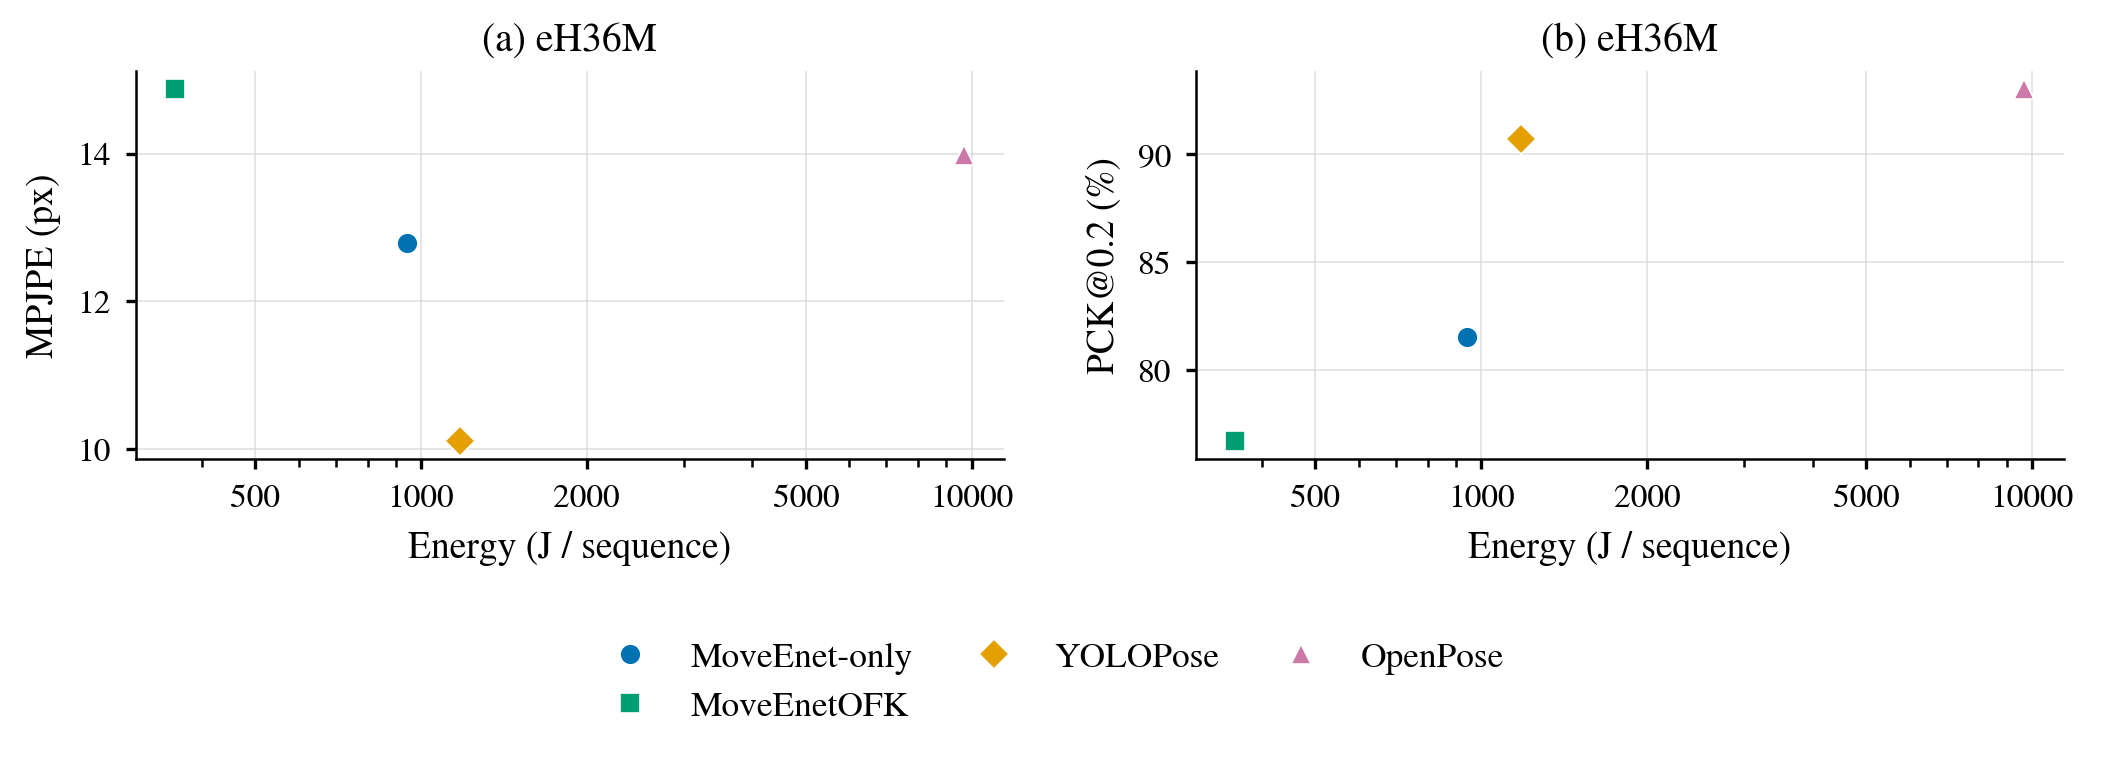

**energy_accuracy/eh36m/pck.png**

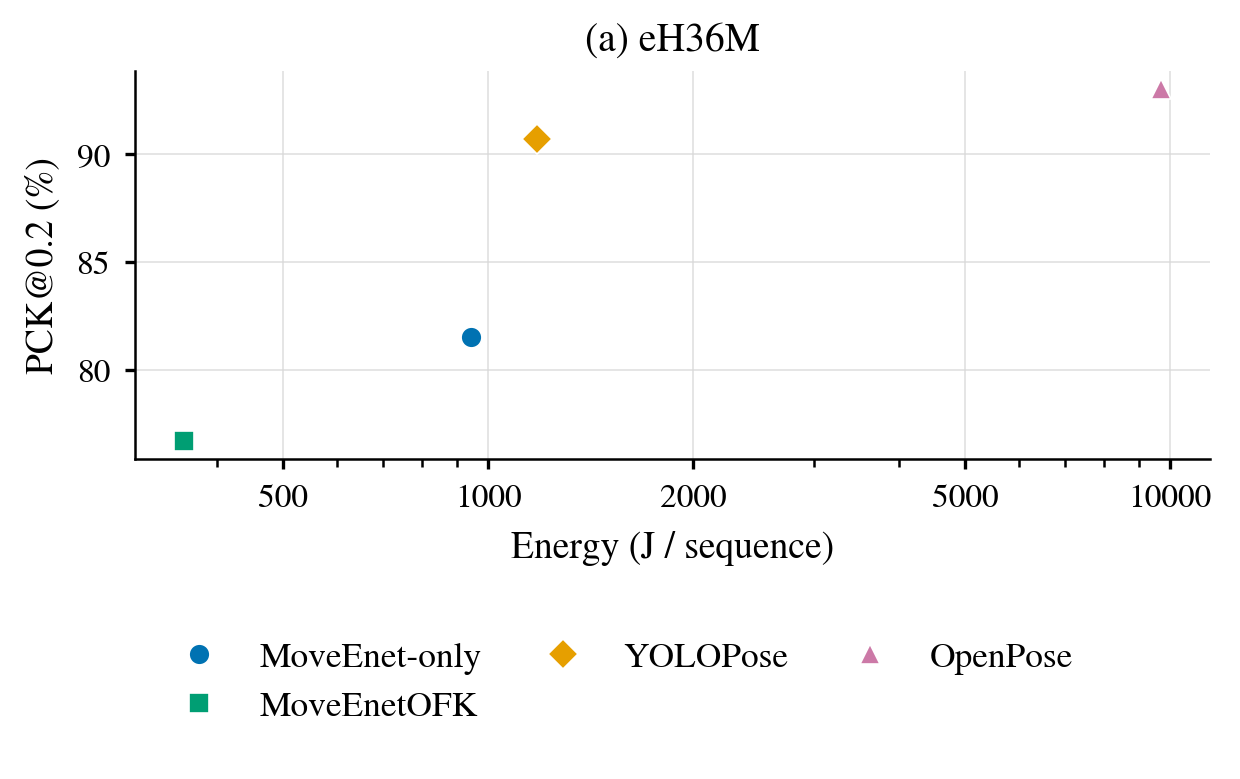

**energy_accuracy/moveiit/mpjpe.png**

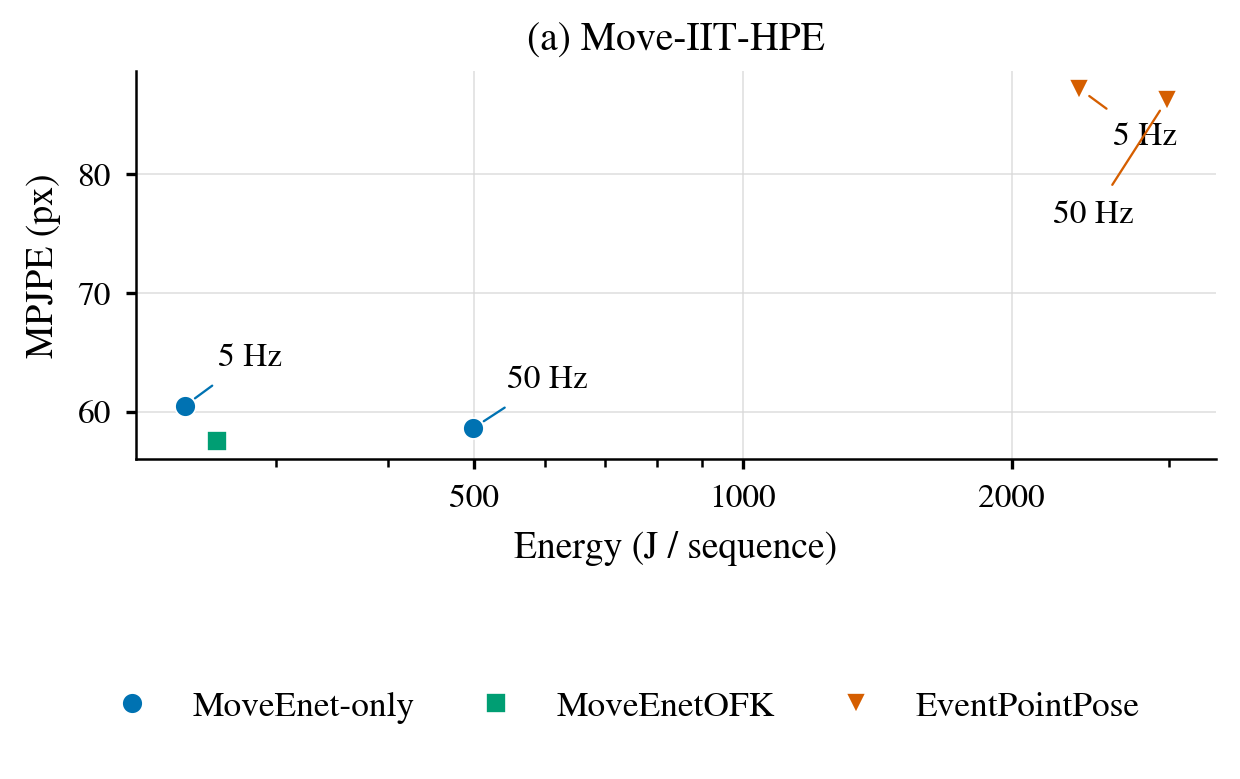

**energy_accuracy/moveiit/mpjpe_pck_pair.png**

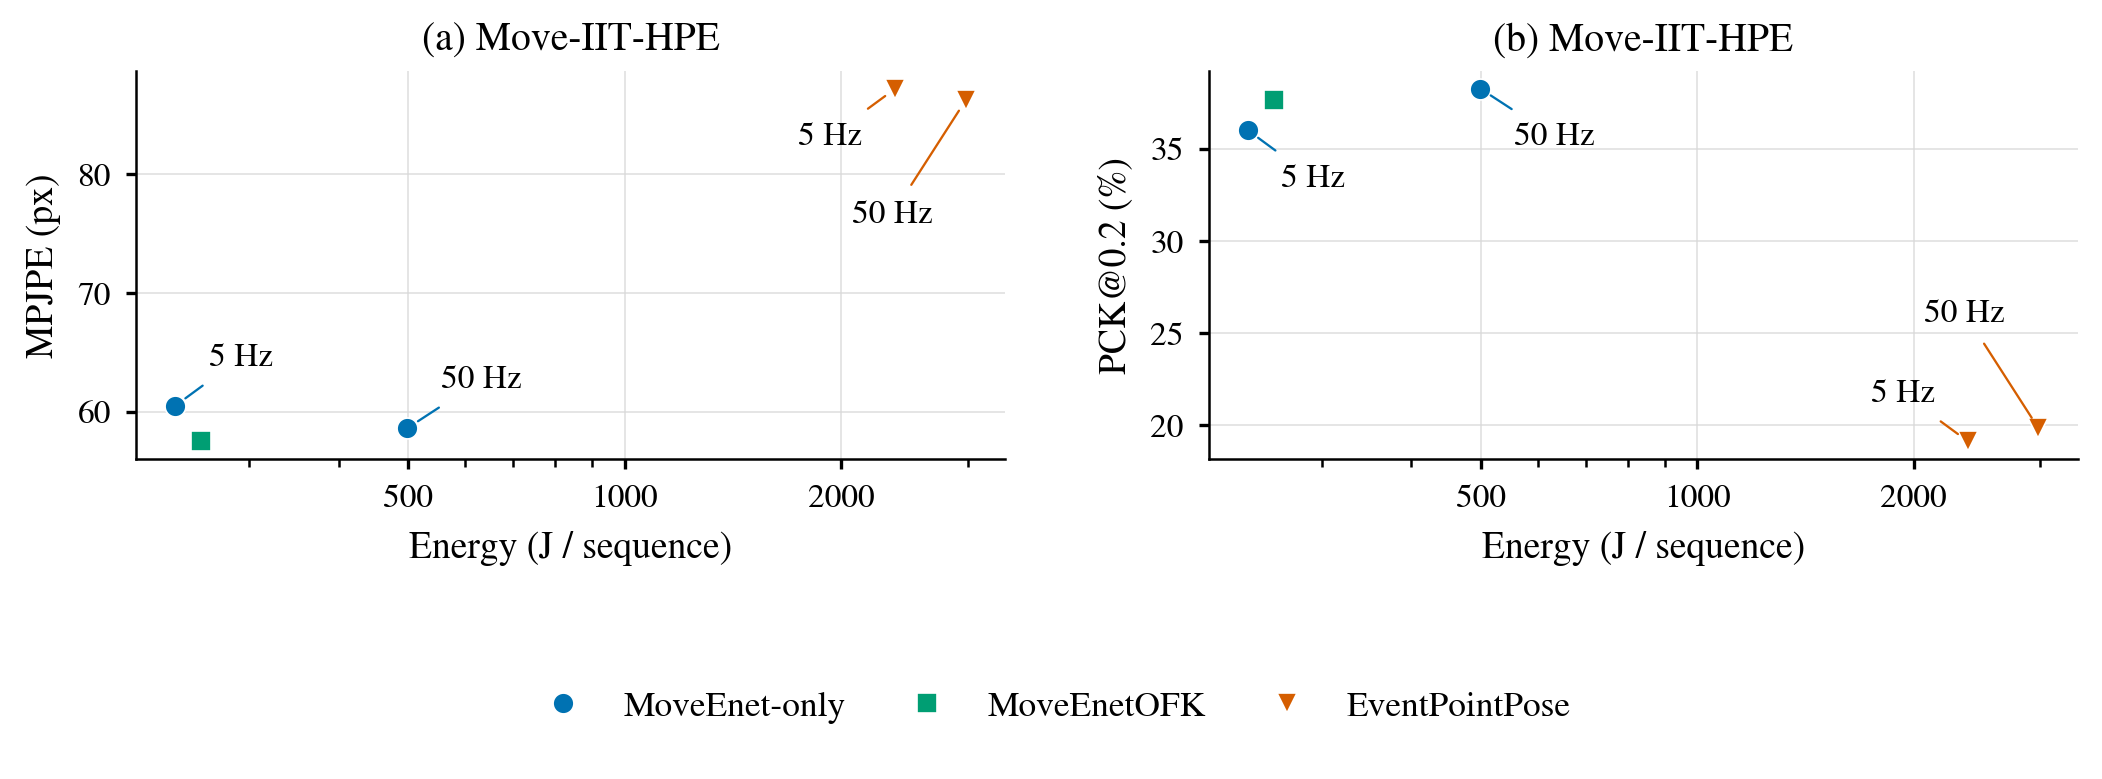

**energy_accuracy/moveiit/pck.png**

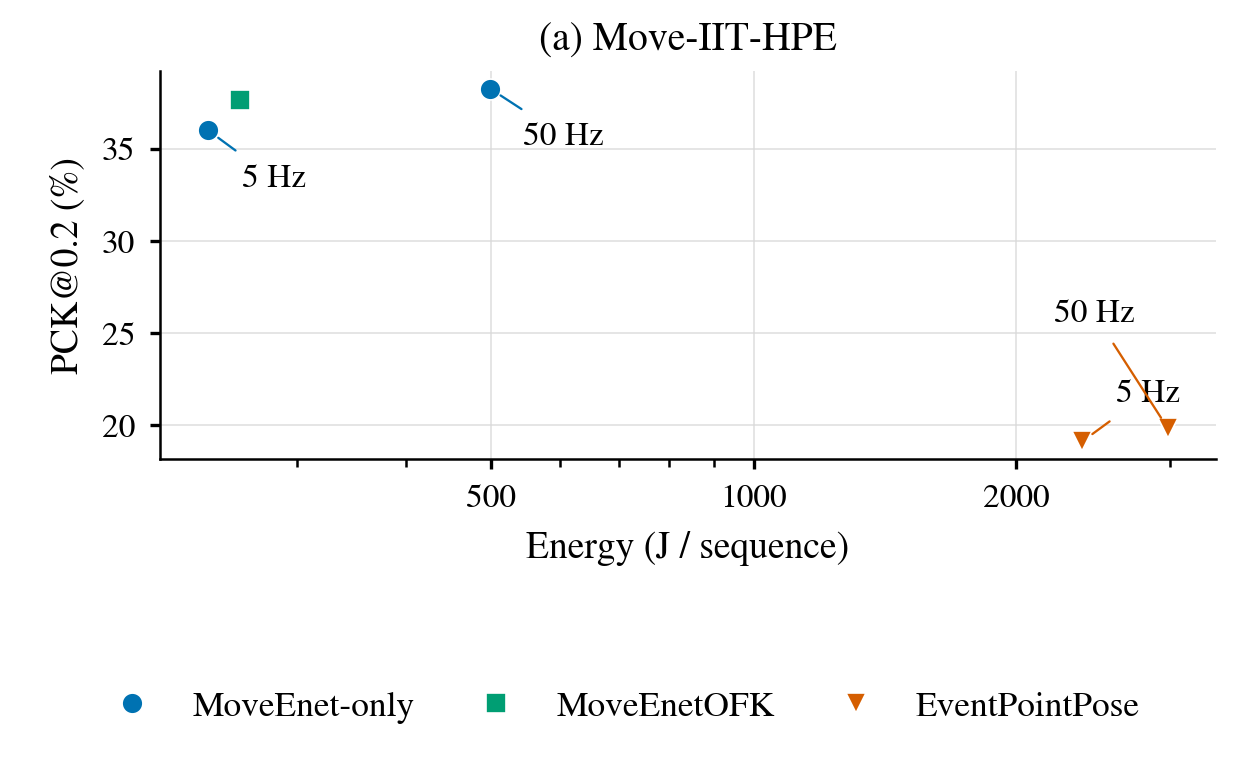

**energy_rtf/moveiit.png**

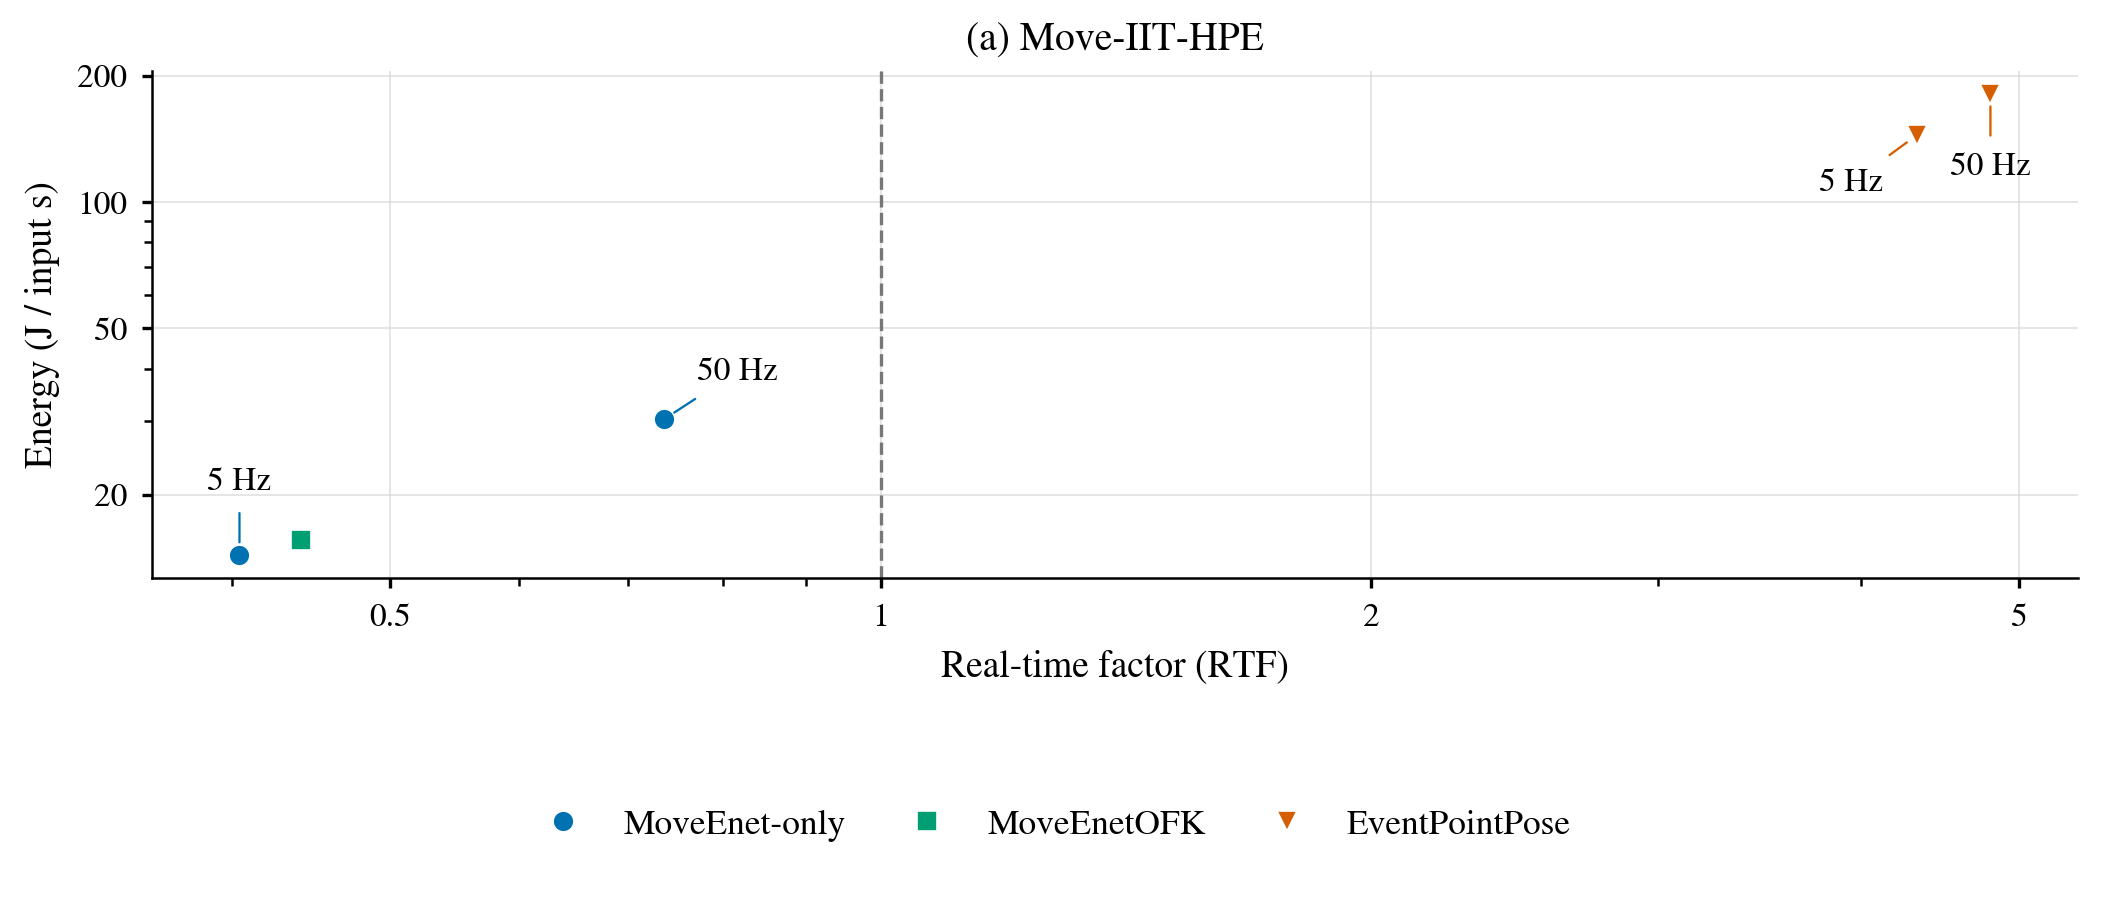

In [5]:
SHOW_FAMILY = 'all'  # 'all', 'energy_accuracy', 'accuracy_rate', 'energy_rtf'
MAX_PREVIEW_WIDTH = 900
pngs = sorted((ROOT/'output').rglob('*.png'))
for path in pngs:
    relative=path.relative_to(ROOT/'output')
    if SHOW_FAMILY != 'all' and relative.parts[0] != SHOW_FAMILY:
        continue
    display(Markdown('**{}**'.format(relative.as_posix())))
    display(Image(filename=str(path),width=MAX_PREVIEW_WIDTH))


## 5. Report delle immagini mancanti

Se l'esperimento eH36M/DHP19 è stato fatto, i valori possono già essere sul tuo PC, ma **non sono stati incorporati nell'anteprima**. Controlla i percorsi nel report e collegali in `sources.json`.


In [6]:
display(Markdown((ROOT/'output/FIGURE_MANIFEST.md').read_text()))


# Generated paper figures

This package exports one **figure per dataset and metric**, plus MPJPE/PCK pairs.
Each figure has **PNG, SVG, PDF** and matching `.meta.json` provenance.

## Created (14 figure stems; 42 exported files)

- `output/energy_accuracy/eh36m/mpjpe`
- `output/energy_accuracy/eh36m/pck`
- `output/energy_accuracy/eh36m/mpjpe_pck_pair`
- `output/energy_accuracy/dhp19/mpjpe`
- `output/energy_accuracy/dhp19/pck`
- `output/energy_accuracy/dhp19/mpjpe_pck_pair`
- `output/energy_accuracy/moveiit/mpjpe`
- `output/energy_accuracy/moveiit/pck`
- `output/energy_accuracy/moveiit/mpjpe_pck_pair`
- `output/energy_accuracy/all_datasets`
- `output/accuracy_rate/moveiit/mpjpe`
- `output/accuracy_rate/moveiit/pck`
- `output/accuracy_rate/moveiit/mpjpe_pck_pair`
- `output/energy_rtf/moveiit`

## Not generated (missing or unverified numerical source)

- accuracy_rate/eh36m: CSV not configured
- accuracy_rate/dhp19: CSV not configured
- energy_rtf/eh36m: CSV not configured
- energy_rtf/dhp19: CSV not configured

## How to enable missing figures

1. Find `*_dataset_metrics.csv` for eH36M/DHP19 ExpA, and `energy_runtime_summary_valid_subset.csv` for normalized energy/RTF.
2. Edit `sources.json` and set the appropriate absolute paths.
3. Run `python generate_all_figures.py` again.

Do not set `expa_pck_1_5_recomputed=true` unless the eH36M/DHP19 PCK summaries have actually been computed with reference joints 1 and 5.


### Stile e limiti

Tutte le figure utilizzano `style.json`: colore/simbolo per ogni metodo, font, dimensioni, spessori, griglia, legende, formati esportati. Modificando `style.json` e rieseguendo la cella 2 rigeneri tutte le immagini coerentemente. I renderer sono in `paper_figures.py`, gli adattatori in `adapters.py`.
